## RAG Day 3

### Expert Question Answerer for InsureLLM

LangChain 1.0 implementation of a RAG pipeline.

Using the VectorStore we created last time (with HuggingFace `all-MiniLM-L6-v2`)

필요한 모듈 임포트

In [1]:

from langchain_chroma import Chroma
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_huggingface import HuggingFaceEmbeddings
import gradio as gr

In [ ]:
from dotenv import load_dotenv
load_dotenv(override=True)

True

데이터 전처리

In [2]:
# LangChain의 로더를 사용하여 지식 베이스의 모든 파일을 불러옵니다
import glob
import os

# 지식 베이스 내 모든 하위 폴더 경로 목록 가져오기
folders = glob.glob("knowledge-base/*")

# LangChain의 문서 로더 임포트
from langchain_community.document_loaders import DirectoryLoader, TextLoader

# 불러온 문서를 저장할 빈 리스트 초기화
documents = []

# 각 폴더를 순회하며 문서 로드
for folder in folders:
    # 폴더명을 문서 타입으로 사용 (예: "products", "faqs" 등)
    doc_type = os.path.basename(folder)

    # 해당 폴더 내 모든 .md 파일을 UTF-8 인코딩으로 불러오는 로더 생성
    loader = DirectoryLoader(
        folder,                          # 탐색할 폴더 경로
        glob="**/*.md",                  # 하위 폴더 포함 모든 .md 파일 대상
        loader_cls=TextLoader,           # 텍스트 파일 로더 사용
        loader_kwargs={'encoding': 'utf-8'}  # UTF-8 인코딩 지정
    )

    # 폴더 내 문서 로드
    folder_docs = loader.load()

    # 각 문서에 메타데이터(문서 타입) 추가 후 전체 리스트에 저장
    for doc in folder_docs:
        doc.metadata["doc_type"] = doc_type  # 어느 폴더 출처인지 태그 추가
        documents.append(doc)

# 총 로드된 문서 수 출력
print(f"총 {len(documents)}개의 문서를 불러왔습니다")

총 76개의 문서를 불러왔습니다


In [3]:
# RecursiveCharacterTextSplitter를 사용하여 문서를 청크(조각)로 분할합니다
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 텍스트 분할기 설정
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,    # 각 청크의 최대 글자 수
    chunk_overlap=200   # 인접한 청크 간 겹치는 글자 수 (문맥 유지용)
)

# 불러온 문서들을 청크로 분할
chunks = text_splitter.split_documents(documents)

# 결과 출력
print(f"총 {len(chunks)}개의 청크로 분할되었습니다")
print(f"첫 번째 청크:\n\n{chunks[0]}")

총 413개의 청크로 분할되었습니다
첫 번째 청크:

page_content='# About Insurellm

Insurellm was founded by Avery Lancaster in 2015 as an insurance tech startup designed to disrupt an industry in need of innovative products. Its first product was Markellm, the marketplace connecting consumers with insurance providers.

The company experienced rapid growth in its first five years, expanding its product portfolio to include Carllm (auto insurance portal), Homellm (home insurance portal), and Rellm (enterprise reinsurance platform). By 2020, Insurellm had reached a peak of 200 employees with 12 offices across the US.' metadata={'source': 'knowledge-base\\company\\about.md', 'doc_type': 'company'}


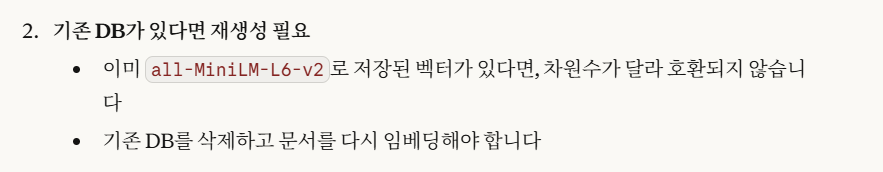

# Pick an embedding model
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
#embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

if os.path.exists(db_name):
    Chroma(persist_directory=db_name, embedding_function=embeddings).delete_collection()

vectorstore = Chroma.from_documents(documents=chunks, embedding=embeddings, persist_directory=db_name)
print(f"Vectorstore created with {vectorstore._collection.count()} documents")

In [4]:
from langchain_openai import ChatOpenAI
from langchain_openai import OpenAIEmbeddings
import os
DB_NAME = "vector_db_small"
#embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma(persist_directory=DB_NAME, embedding_function=embeddings)
if os.path.exists(DB_NAME):
    Chroma(persist_directory=DB_NAME, embedding_function=embeddings).delete_collection()

vectorstore = Chroma.from_documents(documents=chunks, embedding=embeddings, persist_directory=DB_NAME)
print(f"Vectorstore created with {vectorstore._collection.count()} documents")

Vectorstore created with 413 documents


### Set up the 2 key LangChain objects: retriever and llm

#### A sidebar on "temperature":
- Controls how diverse the output is
- A temperature of 0 means that the output should be predictable
- Higher temperature for more variety in answers

Some people describe temperature as being like 'creativity' but that's not quite right
- It actually controls which tokens get selected during inference
- temperature=0 means: always select the token with highest probability
- temperature=1 usually means: a token with 10% probability should be picked 10% of the time

Note: a temperature of 0 doesn't mean outputs will always be reproducible. You also need to set a random seed. We will do that in weeks 6-8. (Even then, it's not always reproducible.)

Note 2: if you want creativity, use the System Prompt!
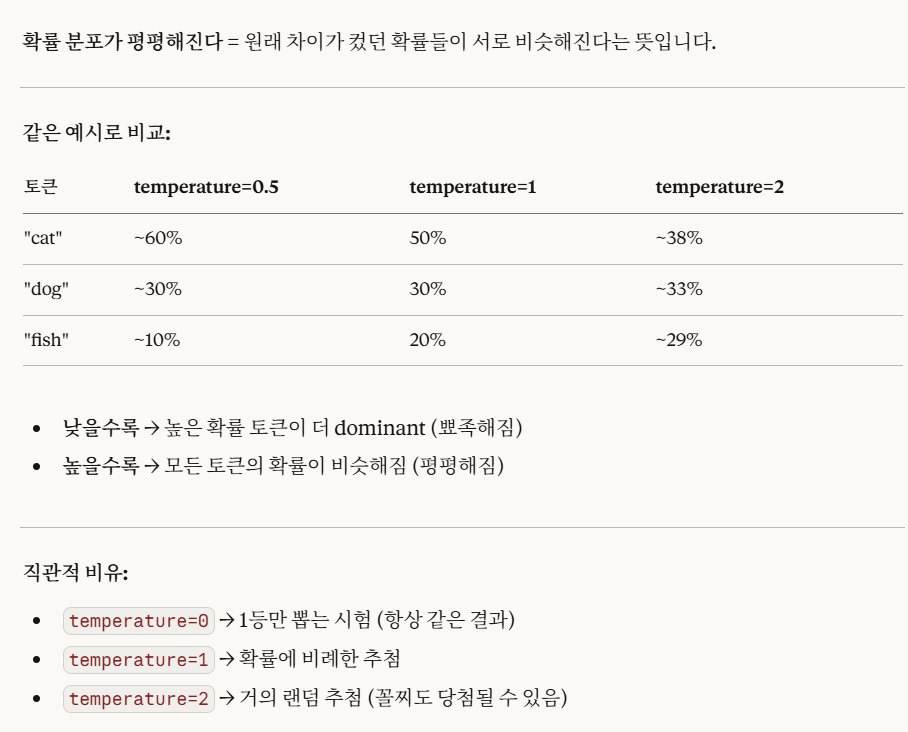

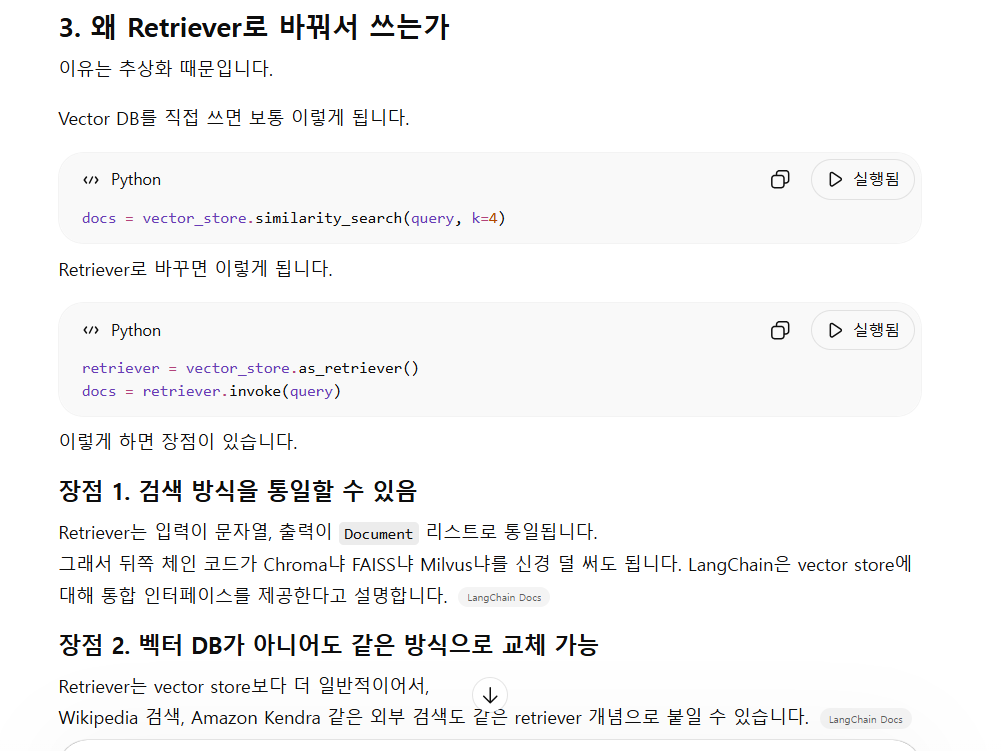

### These LangChain objects implement the method `invoke()`

벡터 스토어에 질문하는것

In [5]:
retriever = vectorstore.as_retriever()

retriever.invoke("Who is Avery?")

[Document(id='91028026-5536-43ea-80fb-39b5e7ba9171', metadata={'doc_type': 'employees', 'source': 'knowledge-base\\employees\\Avery Lancaster.md'}, page_content='# Avery Lancaster\n\n## Summary\n- **Date of Birth**: March 15, 1985\n- **Job Title**: Co-Founder & Chief Executive Officer (CEO)\n- **Location**: San Francisco, California\n- **Current Salary**: $225,000  \n\n## Insurellm Career Progression\n- **2015 - Present**: Co-Founder & CEO  \n  Avery Lancaster co-founded Insurellm in 2015 and has since guided the company to its current position as a leading Insurance Tech provider. Avery is known for her innovative leadership strategies and risk management expertise that have catapulted the company into the mainstream insurance market.  \n\n- **2013 - 2015**: Senior Product Manager at Innovate Insurance Solutions  \n  Before launching Insurellm, Avery was a leading Senior Product Manager at Innovate Insurance Solutions, where she developed groundbreaking insurance products aimed at the

ChatGPT에게 질문 하는것

In [6]:
MODEL = "gpt-4.1-nano"

# temperature=0 means: always select the token with highest probability
#- temperature=1 usually means: a token with 10% probability should be picked 10% of the time
llm = ChatOpenAI(temperature=0, model_name=MODEL)

In [7]:
llm.invoke("Who is Avery?")

AIMessage(content="Could you please provide more context or specify which Avery you're referring to? There are many individuals and characters named Avery.", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 11, 'total_tokens': 34, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-nano-2025-04-14', 'system_fingerprint': 'fp_56597d1d69', 'id': 'chatcmpl-DnJ5cX5drXPIUCff7FQYXdSZLJeqh', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019e96a4-7e36-7b61-aabf-9317475b2950-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 11, 'output_tokens': 23, 'total_tokens': 34, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning':

## Time to put this together!

In [8]:
SYSTEM_PROMPT_TEMPLATE = """
당신은 Insurellm 회사를 대표하는 친절하고 전문적인 어시스턴트입니다.
사용자와 Insurellm에 대해 대화하고 있습니다.
관련이 있는 경우, 주어진 컨텍스트를 활용하여 질문에 답변하세요.
답을 모를 경우에는 모른다고 말씀해 주세요.
컨텍스트:
{context}
"""

하나의 함수로 벡터 조회후 결과를  chatGPT 에게 넘기여서 
chatgpt가 LAG 가 반영된 결과를 받음

In [9]:
def answer_question(question: str, history):
    docs = retriever.invoke(question)
    context = "\n\n".join(doc.page_content for doc in docs)
    system_prompt = SYSTEM_PROMPT_TEMPLATE.format(context=context)
    response = llm.invoke([SystemMessage(content=system_prompt), HumanMessage(content=question)])
    return response.content

In [10]:
answer_question("Who is Averi Lancaster?", [])

'Avery Lancaster is the Co-Founder and Chief Executive Officer (CEO) of Insurellm. She co-founded the company in 2015 and has been leading it since then, guiding it to become a prominent player in the insurance technology industry. Avery is known for her innovative leadership and expertise in risk management.'

## What could possibly come next? 😂

Who is Averi Lancaster?
how much is her salary?

In [11]:
gr.ChatInterface(answer_question).launch()

c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\gradio\chat_interface.py:347: UserWarning: The 'tuples' format for chatbot messages is deprecated and will be removed in a future version of Gradio. Please set type='messages' instead, which uses openai-style 'role' and 'content' keys.
  self.chatbot = Chatbot(


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Admit it - you thought RAG would be more complicated than that!!